In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
import seaborn as sns
import csv

# Set the path to the folder with the throughput results
basepath = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/tp_res_1/"

# Read Throughput from CSV files and return a list
def readThroughput(pathname):
    throughputs = {}
    times = [1, 10, 100, 1000]

    # Go trough all the coherence times
    for i in times:
        throughputs[i] = []

        # Go through the number of experiments
        for j in range (100):
            fname = f"{basepath}throughput_results_{i}_{j+1}.csv"
            try:
                with open(fname, newline='') as csvfile:
                    spamreader = csv.reader(csvfile, delimiter=' ', quotechar='|')
                    # Skip the header line, Strings make for terrible numbers
                    header = next(spamreader, None)

                    # Put the data from the csv into the dictionary at the coherence time
                    for row in spamreader:
                        t_var = ', '.join(row).split(",")[1]
                        throughputs[i].append(float(t_var))
            except FileNotFoundError:
                # print("File ", fname, " not found")
                continue
    # Return all the throughput values at one
    return [throughputs[1], throughputs[10], throughputs[100],throughputs[1000]]

throughput = readThroughput(basepath)

box_plot = sns.boxplot(data=throughput, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(t) for t in throughput]

vertical_offset = [m * 0.01 for m in medians]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + vertical_offset[xtick],
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='black',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Mbps")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 180)

plt.title("Throughput Boxplot, TCP Cubic, 20MHz channel, high mobility")
#plt.title("Throughput Boxplot, TCP Cubic, 80MHz channel, low mobility, outdoor munich")
#plt.savefig("throughput_boxplot.png")

# TODO: Why some very high throughput sometimes?
# plt.savefig("throughput_boxplot.png")
# TODO: Look into logging modulation and coding scheme
# TODO: Check via rolling average if throughput measurements of 10ms and 100ms are the same
# Update mitsuba
# TODO: No zero values, or stop measuring after 0 measurement
# SNR of munich, cfr tag with coherence time
# Example for issue for mitsuba in python


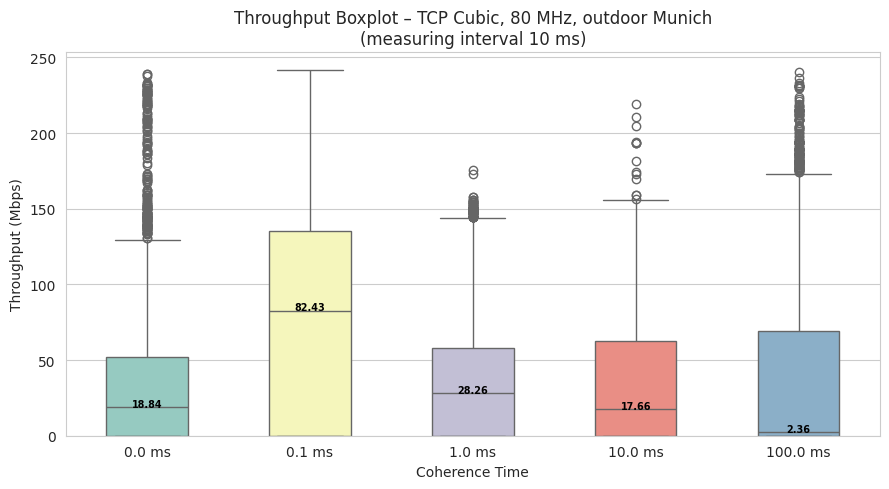

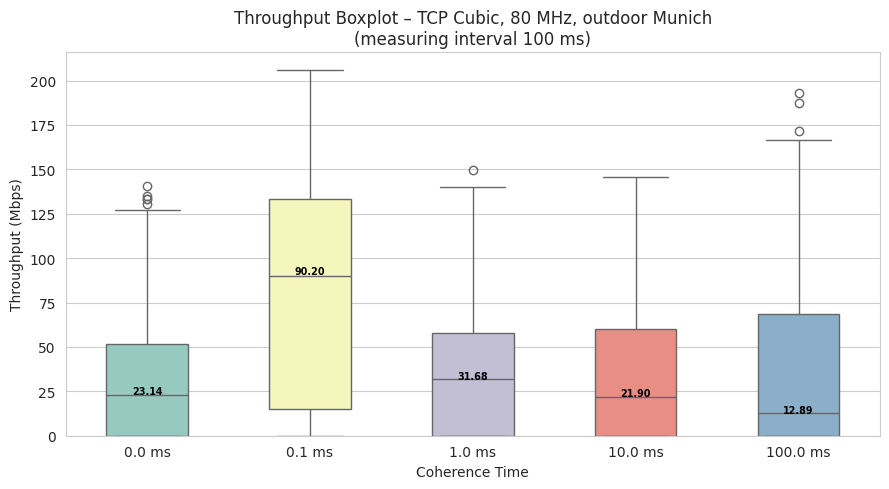

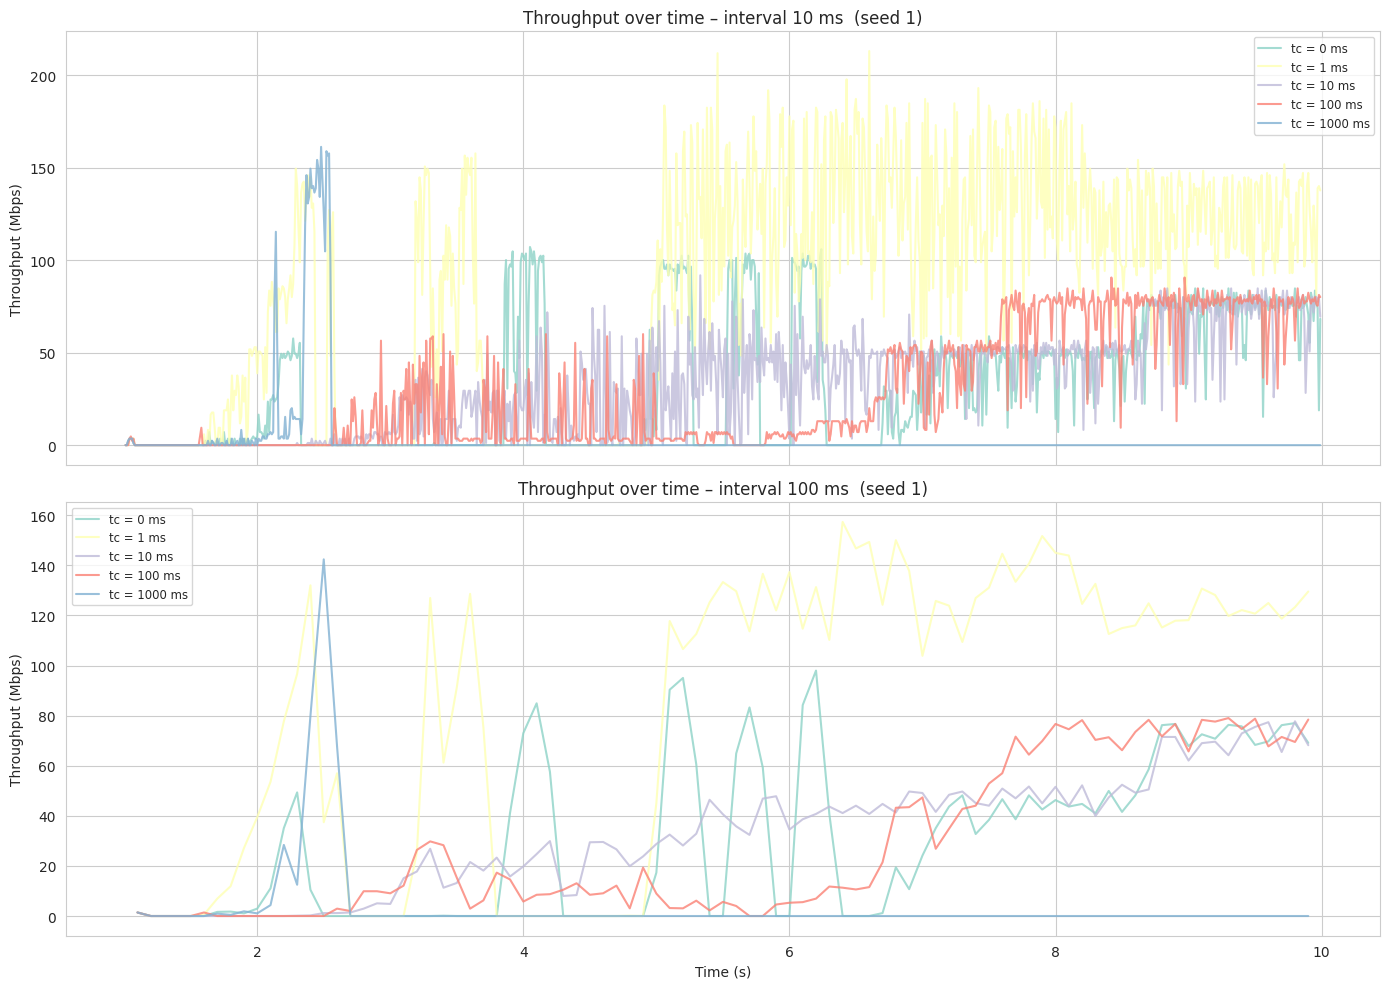

In [8]:
"""
Throughput plotting script for the Munich outdoor scenario.

Reads throughput CSV files produced by the Munich ns-3 simulation
(via the watchdog-munich.sh / runner-munich.sh pipeline) and
generates publication-quality plots.

Expected CSV layout (per file):
    Time,Throughput_Mbps,measuring interval in ms
    <float>,<float>,<int: 10 or 100>

File naming convention:
    results-munich/tc{coherence}/throughput_results_{coherence}_{seed}.csv
"""

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── Configuration ────────────────────────────────────────────────────────
RESULTS_BASE = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/results-munich/"

COHERENCE_TIMES = [0, 1, 10, 100, 1000]   # ms – must match watchdog
START_SEED = 1
END_SEED   = 10                         # inclusive

MEASURING_INTERVALS = [10, 100]         # ms – the two cadences used in the C++ code

# ── Helpers ──────────────────────────────────────────────────────────────

def tp_path(tc: int, seed: int) -> str:
    """Return the expected path for a throughput CSV."""
    return os.path.join(
        RESULTS_BASE,
        f"tc{tc}",
        f"throughput_results_{tc}_{seed}.csv",
    )


def read_throughput_file(path: str):
    """
    Parse a single throughput CSV produced by the Munich simulation.

    Returns
    -------
    dict  –  keys are measuring-interval values (10, 100);
             values are lists of (time, throughput_mbps) tuples.
    """
    result = {iv: [] for iv in MEASURING_INTERVALS}
    try:
        with open(path, newline="") as fh:
            reader = csv.reader(fh)
            header = next(reader, None)          # skip header line
            if header is None:
                return result
            for row in reader:
                if len(row) < 3:
                    continue
                try:
                    t   = float(row[0].strip())
                    tp  = float(row[1].strip())
                    iv  = int(float(row[2].strip()))
                except (ValueError, IndexError):
                    continue
                if iv in result:
                    result[iv].append((t, tp))
    except FileNotFoundError:
        pass
    return result


def collect_throughput_values(interval_ms: int):
    """
    Collect *all* throughput samples across every coherence time and seed
    for one measuring interval.

    Returns
    -------
    dict  –  {coherence_time: [throughput_values]}
    """
    data = {tc: [] for tc in COHERENCE_TIMES}
    for tc in COHERENCE_TIMES:
        for seed in range(START_SEED, END_SEED + 1):
            parsed = read_throughput_file(tp_path(tc, seed))
            for (_t, tp) in parsed.get(interval_ms, []):
                data[tc].append(tp)
    return data


# ── Plot 1: Boxplot of throughput per coherence time ─────────────────────

def plot_throughput_boxplot(interval_ms: int):
    """One boxplot per coherence time, for a given measuring interval."""
    data = collect_throughput_values(interval_ms)
    values = [data[tc] for tc in COHERENCE_TIMES]
    labels = [f"{tc/10} ms" for tc in COHERENCE_TIMES]

    fig, ax = plt.subplots(figsize=(9, 5))
    bp = sns.boxplot(data=values, ax=ax, widths=0.5)

    medians = [np.median(v) if v else float("nan") for v in values]
    for xtick in bp.get_xticks():
        m = medians[xtick]
        if not np.isnan(m):
            bp.text(
                xtick,
                m + abs(m) * 0.01,
                f"{m:.2f}",
                horizontalalignment="center",
                size="x-small",
                color="black",
                weight="semibold",
            )

    ax.set_xticks(range(len(COHERENCE_TIMES)))
    ax.set_xticklabels(labels)
    ax.set_xlabel("Coherence Time")
    ax.set_ylabel("Throughput (Mbps)")
    ax.set_title(
        f"Throughput Boxplot – TCP Cubic, 80 MHz, outdoor Munich\n"
        f"(measuring interval {interval_ms} ms)"
    )
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.savefig(
        f"throughput_boxplot_{interval_ms}ms.png",
        dpi=300, bbox_inches="tight", pad_inches=0.2,
    )
    plt.show()


# ── Plot 2: Throughput over time for a single seed ───────────────────────

def plot_throughput_over_time(seed: int = 1):
    """Line plot of throughput vs. time for every coherence time (one seed)."""
    fig, axes = plt.subplots(
        len(MEASURING_INTERVALS), 1,
        figsize=(14, 5 * len(MEASURING_INTERVALS)),
        sharex=True,
    )
    if len(MEASURING_INTERVALS) == 1:
        axes = [axes]

    for ax, iv in zip(axes, MEASURING_INTERVALS):
        for tc in COHERENCE_TIMES:
            parsed = read_throughput_file(tp_path(tc, seed))
            pts = parsed.get(iv, [])
            if not pts:
                continue
            times = [p[0] for p in pts]
            tps   = [p[1] for p in pts]
            ax.plot(times, tps, label=f"tc = {tc} ms", alpha=0.8)

        ax.set_ylabel("Throughput (Mbps)")
        ax.set_title(f"Throughput over time – interval {iv} ms  (seed {seed})")
        ax.legend(fontsize="small")

    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.savefig(
        f"throughput_over_time_seed{seed}.png",
        dpi=300, bbox_inches="tight", pad_inches=0.3,
    )
    plt.show()


# ── Main ─────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    for iv in MEASURING_INTERVALS:
        plot_throughput_boxplot(iv)
    plot_throughput_over_time(seed=1)

    # SNR Plot
    # Upload csv
    # TODO: Unterschiedliche raeume
    # TODO: 10dBm

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import seaborn as sns
import csv

# Configuration - adjust these to match your simulation runs
BASE_PATH = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/results/"

# Coherence times swept in the simulation (must match watchdog.sh)
COHERENCE_TIMES = [1, 10, 100, 1000]

# Measurement intervals to compare (in ms)
MEASUREMENT_INTERVALS = [10, 100]

# Seed range (must match START_SEED and END_SEED in watchdog.sh)
START_SEED = 1
END_SEED = 10

# Channel configuration (for plot title)
CHANNEL_WIDTH = "80MHz"  # or "20MHz"
MOBILITY = "high mobility"  # or "low mobility"


def read_throughput(basepath, coherence_times, start_seed, end_seed, measurement_interval_ms):
    """
    Read throughput data from CSV files for a given measurement interval.

    Expected file format: throughput_results_{coherence_time}_{seed}.csv
    CSV format: Time, Throughput_Mbps, measuring interval in ms

    Returns:
        Dictionary mapping coherence time -> list of throughput values
    """
    throughputs = {}

    for tc in coherence_times:
        throughputs[tc] = []

        for seed in range(start_seed, end_seed + 1):
            fname = os.path.join(basepath, f"interval{measurement_interval_ms}", f"tc{tc}",
                                 f"throughput_results_{tc}_{seed}.csv")

            try:
                with open(fname, 'r') as csvfile:
                    reader = csv.reader(csvfile)

                    # Skip header line
                    next(reader, None)

                    for row in reader:
                        if len(row) >= 2:
                            try:
                                throughput_val = float(row[1])
                                throughputs[tc].append(throughput_val)
                            except ValueError:
                                continue

            except FileNotFoundError:
                continue
            except Exception as e:
                print(f"Error reading {fname}: {e}")
                continue

    return throughputs


def create_boxplot_ax(ax, throughputs, coherence_times, measurement_interval_ms):
    """
    Draw a boxplot of throughput vs coherence time onto an existing Axes object.
    """
    data = [throughputs[tc] for tc in coherence_times]

    # Filter out empty series to avoid seaborn errors
    valid_indices = [i for i, d in enumerate(data) if d]
    valid_data = [data[i] for i in valid_indices]
    valid_tcs = [coherence_times[i] for i in valid_indices]

    if not valid_data:
        ax.text(0.5, 0.5, "No data available", ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f"Measurement interval: {measurement_interval_ms} ms")
        return

    box_plot = sns.boxplot(
        data=valid_data,
        width=0.5,
        palette="Blues",
        ax=ax
    )

    # Median annotations
    medians = [np.median(d) for d in valid_data]
    for xtick, median in enumerate(medians):
        box_plot.text(
            xtick,
            median + median * 0.015,
            f'{median:.2f}',
            horizontalalignment='center',
            size='x-small',
            color='black',
            weight='semibold'
        )

    # Stats text box
    stats_text = ""
    for tc, d in zip(valid_tcs, valid_data):
        stats_text += f"{tc/10:.1f}ms: μ={np.mean(d):.2f}, σ={np.std(d):.2f}, n={len(d)}\n"

    ax.text(
        0.02, 0.98, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=8,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    )

    ax.set_xlabel("Coherence Time (ms)", fontsize=11)
    ax.set_ylabel("Throughput (Mbps)", fontsize=11)

    tick_labels = [f"{tc/10:.1f} ms" for tc in valid_tcs]
    ax.set_xticks(range(len(valid_tcs)))
    ax.set_xticklabels(tick_labels)

    all_vals = [v for d in valid_data for v in d]
    ax.set_ylim(0, max(all_vals) * 1.15)

    ax.set_title(f"Measurement interval: {measurement_interval_ms} ms", fontsize=12)


def create_combined_plot(all_throughputs, coherence_times, measurement_intervals, output_path=None):
    """
    Create a side-by-side boxplot figure comparing multiple measurement intervals.
    """
    sns.set_style("whitegrid")

    fig, axes = plt.subplots(1, len(measurement_intervals), figsize=(7 * len(measurement_intervals), 6),
                             sharey=True)

    # If only one interval, axes won't be a list
    if len(measurement_intervals) == 1:
        axes = [axes]

    for ax, interval_ms in zip(axes, measurement_intervals):
        create_boxplot_ax(ax, all_throughputs[interval_ms], coherence_times, interval_ms)

    # Only the leftmost subplot needs a y-label when sharing the y-axis
    for ax in axes[1:]:
        ax.set_ylabel("")

    fig.suptitle(
        f"Throughput vs Coherence Time\n"
        f"TCP Cubic, {CHANNEL_WIDTH} channel, {MOBILITY}",
        fontsize=14
    )

    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {output_path}")
    else:
        plt.show()

    return fig


def main():
    print("=" * 60)
    print("Throughput Plotting Script")
    print("=" * 60)
    print(f"Base path:            {BASE_PATH}")
    print(f"Coherence times:      {COHERENCE_TIMES}")
    print(f"Measurement intervals:{MEASUREMENT_INTERVALS} ms")
    print(f"Seed range:           {START_SEED} to {END_SEED}")
    print()

    if not os.path.exists(BASE_PATH):
        print(f"ERROR: Base path does not exist: {BASE_PATH}")
        return

    all_throughputs = {}

    for interval_ms in MEASUREMENT_INTERVALS:
        print(f"--- Measurement interval: {interval_ms} ms ---")
        for tc in COHERENCE_TIMES:
            dir_path = os.path.join(BASE_PATH, f"interval{interval_ms}", f"tc{tc}")
            if os.path.exists(dir_path):
                files = [f for f in os.listdir(dir_path) if f.startswith("throughput_results_")]
                print(f"  tc{tc}: {len(files)} files found")
            else:
                print(f"  tc{tc}: directory not found ({dir_path})")

        print(f"  Reading data...")
        throughputs = read_throughput(BASE_PATH, COHERENCE_TIMES, START_SEED, END_SEED, interval_ms)
        all_throughputs[interval_ms] = throughputs

        print(f"  Summary:")
        for tc in COHERENCE_TIMES:
            d = throughputs[tc]
            if d:
                print(f"    {tc/10:.1f}ms coherence: {len(d)} samples, "
                      f"median={np.median(d):.2f} Mbps, mean={np.mean(d):.2f} Mbps")
            else:
                print(f"    {tc/10:.1f}ms coherence: no data")
        print()

    print("Creating plot...")
    output_filename = (f"throughput_boxplot_intervals"
                       f"{'_'.join(map(str, MEASUREMENT_INTERVALS))}ms.png")
    output_path = os.path.join(BASE_PATH, output_filename)

    create_combined_plot(all_throughputs, COHERENCE_TIMES, MEASUREMENT_INTERVALS, output_path)
    print("Done!")


if __name__ == "__main__":
    main()

['.idea', 'LICENSE', 'common', 'models', 'ns3sionna_utils.py', 'run_fast.sh', 'run_python_proto.sh', 'tests', '__pycache__', '.DS_Store', 'README.md', 'mobility.py', 'ns3sionna_server.py', 'requirements.txt', 'requirements_cpuonly.txt', 'run_unit_tests.sh', 'run.sh', 'run_incomp.sh', 'stepcounter.txt', 'server.log']


Text(0.5, 1.0, 'Computation time to fixed coherence time')

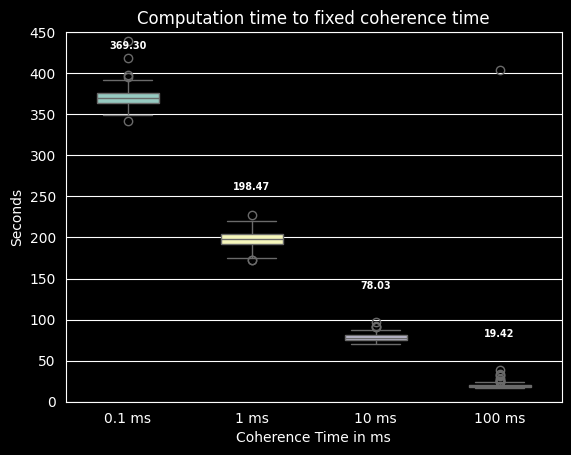

In [9]:
# Plot the time
timepath = '/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/computationtimeHighMobility.csv'
print(os.listdir('../model/ns3sionna'))

def readTime(fname):
    comp_times = {}
    times = [1, 10, 100, 1000]
    # Setup dict
    for i in times:
        comp_times[i] = []
    try:
        with open(fname, newline='') as csvfile:
            spamreader = csv.reader(csvfile, delimiter=',', quotechar='|')
            # Put the data from the csv into the dictionary at the coherence time
            for line in spamreader:
                # Line value is a string, turn into int to use as index
                comp_times[int(line[0])].append(float(line[1]))
    except FileNotFoundError:
        print(f"Could not {timepath} file.")

    return comp_times

timeValue = readTime(timepath)

# print(timeValue)

box_plot = sns.boxplot(data=timeValue, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(timeValue[t]) for t in timeValue]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + 60,
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='white',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Seconds")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 450)

plt.title("Computation time to fixed coherence time")

In [8]:
import pandas as pd


'''
results_base = ".../examples/results-munich/"
AP_X, AP_Y   = 8.5, 21.0      # Munich AP position (from the C++ file)
TX_POWER_DBM = 30.0            # Munich default TX power
'''

results_base = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/results/"
# TODO: Change location of results to munich, change Transmit power as well.

coherence_times = [1, 10, 100, 1000]   # ms  — must match COHERENCE_TIMES in watchdog.sh
num_seeds       = 10                 # END_SEED value used in watchdog.sh

# AP position in the floor-plan (metres) — update to match your C++ scenario
AP_X, AP_Y = -1.0, 0.5

# TX power used in the simulation (dBm) — must match TX_POWER_DBM in the C++ file
TX_POWER_DBM = 20.0


def snr_file(tc, seed):
    return f"{results_base}tc{tc}/snr_results_{tc}_{seed}.csv"

def pos_file(tc, seed):
    return f"{results_base}tc{tc}/position_results_{tc}_{seed}.csv"

def tp_file(tc, seed):
    return f"{results_base}tc{tc}/throughput_results_{tc}_{seed}.csv"


def load_csv(path):
    """Return DataFrame or None if the file is missing."""
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return None


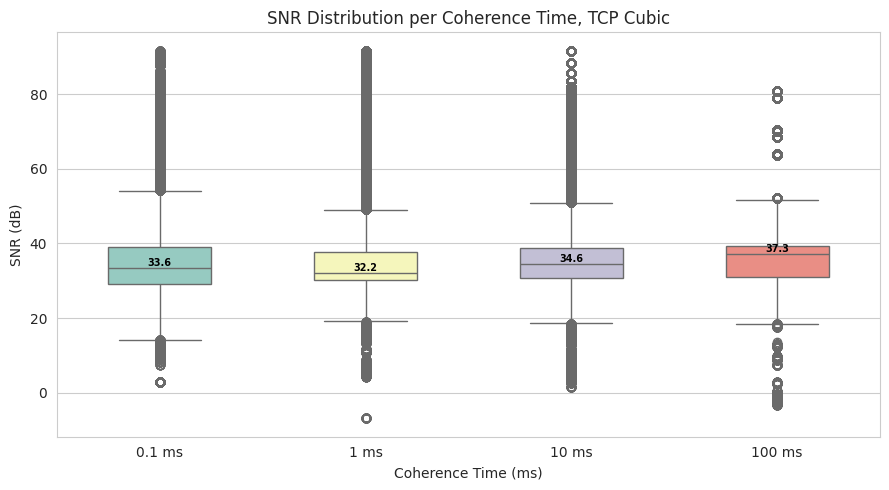

In [9]:
# SNR Plot
snr_by_tc = {tc: [] for tc in coherence_times}

for tc in coherence_times:
    for seed in range(1, num_seeds + 1):
        df = load_csv(snr_file(tc, seed))
        if df is not None:
            snr_by_tc[tc].extend(df['SNR_dB'].tolist())

data_list = [snr_by_tc[tc] for tc in coherence_times]
labels    = [f"{tc} ms" for tc in coherence_times]

fig, ax = plt.subplots(figsize=(9, 5))
bp = sns.boxplot(data=data_list, ax=ax, widths=0.5)

medians  = [np.median(d) if d else float('nan') for d in data_list]
v_off    = [abs(m) * 0.01 for m in medians]
for xtick in bp.get_xticks():
    if not np.isnan(medians[xtick]):
        bp.text(xtick, medians[xtick] + v_off[xtick],
                f'{medians[xtick]:.1f}',
                ha='center', size='x-small', color='black', weight='semibold')

ax.set_xticks(range(len(coherence_times)))
ax.set_xticklabels(labels)
ax.set_xlabel('Coherence Time (ms)')
ax.set_ylabel('SNR (dB)')
ax.set_title('SNR Distribution per Coherence Time, TCP Cubic')
plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.tight_layout()
plt.savefig('snr_boxplot.png', dpi=300, bbox_inches='tight', pad_inches=0.2)
plt.show()


In [35]:
import pandas as pd


'''
results_base = ".../examples/results-munich/"
AP_X, AP_Y   = 8.5, 21.0      # Munich AP position (from the C++ file)
TX_POWER_DBM = 30.0            # Munich default TX power
'''

results_base = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/results/"
# TODO: Change location of results to munich, change Transmit power as well.

coherence_times = [1, 10, 100, 1000]   # ms  — must match COHERENCE_TIMES in watchdog.sh
num_seeds       = 10                 # END_SEED value used in watchdog.sh

# AP position in the floor-plan (metres) — update to match your C++ scenario
AP_X, AP_Y = -1.0, 0.5

# TX power used in the simulation (dBm) — must match TX_POWER_DBM in the C++ file
TX_POWER_DBM = 20.0


def snr_file(tc, seed):
    return f"{results_base}tc{tc}/snr_results_{tc}_{seed}.csv"

def pos_file(tc, seed):
    return f"{results_base}tc{tc}/position_results_{tc}_{seed}.csv"

def tp_file(tc, seed):
    return f"{results_base}tc{tc}/throughput_results_{tc}_{seed}.csv"


def load_csv(path):
    """Return DataFrame or None if the file is missing."""
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return None


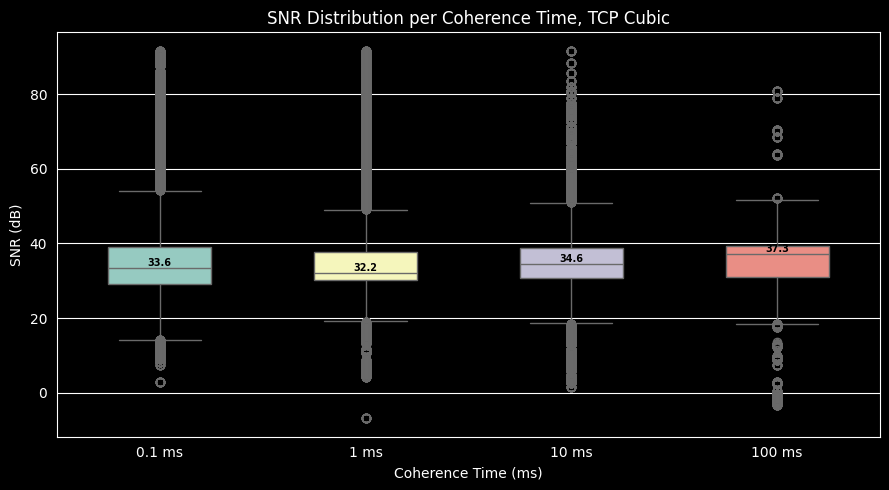

In [36]:
# SNR Plot
snr_by_tc = {tc: [] for tc in coherence_times}

for tc in coherence_times:
    for seed in range(1, num_seeds + 1):
        df = load_csv(snr_file(tc, seed))
        if df is not None:
            snr_by_tc[tc].extend(df['SNR_dB'].tolist())

data_list = [snr_by_tc[tc] for tc in coherence_times]
labels    = [f"{tc} ms" for tc in coherence_times]

fig, ax = plt.subplots(figsize=(9, 5))
bp = sns.boxplot(data=data_list, ax=ax, widths=0.5)

medians  = [np.median(d) if d else float('nan') for d in data_list]
v_off    = [abs(m) * 0.01 for m in medians]
for xtick in bp.get_xticks():
    if not np.isnan(medians[xtick]):
        bp.text(xtick, medians[xtick] + v_off[xtick],
                f'{medians[xtick]:.1f}',
                ha='center', size='x-small', color='black', weight='semibold')

ax.set_xticks(range(len(coherence_times)))
ax.set_xticklabels(labels)
ax.set_xlabel('Coherence Time (ms)')
ax.set_ylabel('SNR (dB)')
ax.set_title('SNR Distribution per Coherence Time, TCP Cubic')
plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.tight_layout()
plt.savefig('snr_boxplot.png', dpi=300, bbox_inches='tight', pad_inches=0.2)
plt.show()


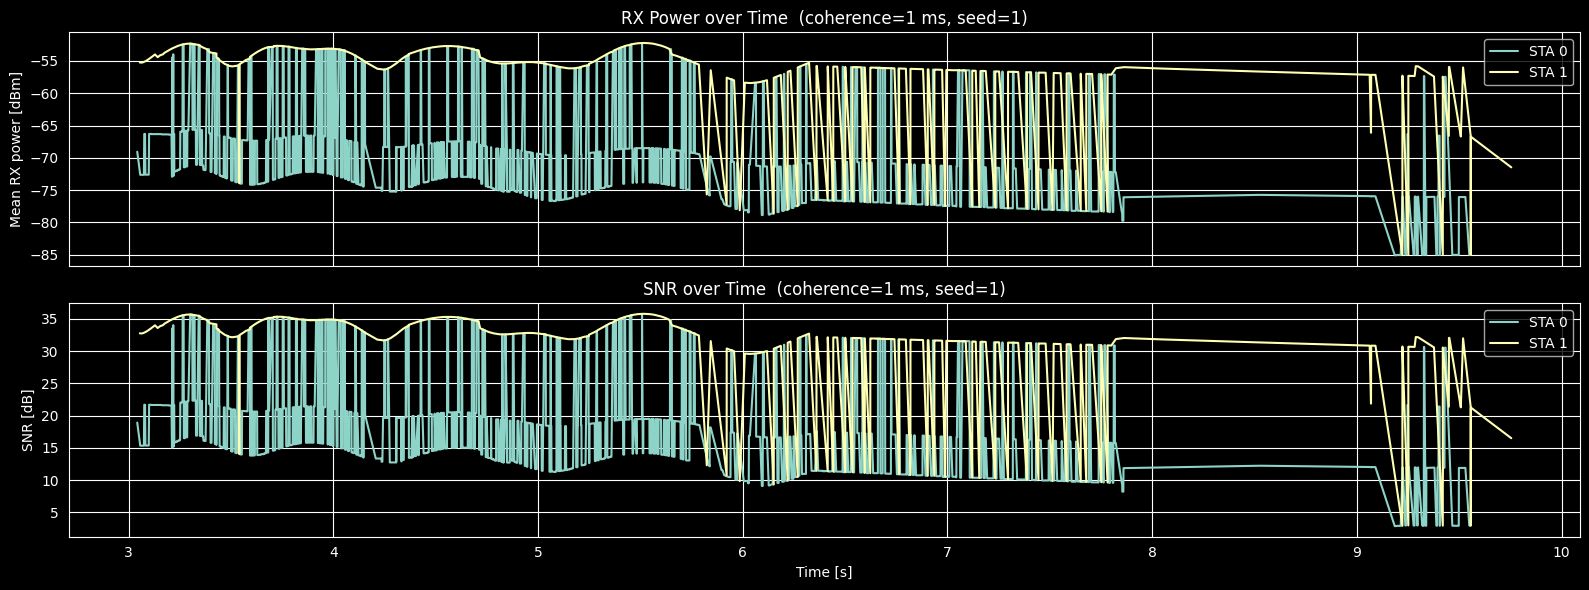

In [41]:
# ── 2. RX power and SNR over time (representative run, seed=1) ───────────
# Mirrors the pathloss-over-time line plot from plot3d_mobile_csi.py.
tc_ex = coherence_times[0]
df_ex = load_csv(snr_file(tc_ex, 1))
# TODO: Make seed as clear setting
# TODO: Make plotting for throughput work again
# TODO: Munich has not finished the simulation.
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)

if df_ex is not None and not df_ex.empty:
    for sta_id, grp in df_ex.groupby('STA_NodeId'):
        grp = grp.sort_values('Time_s')
        axes[0].plot(grp['Time_s'], grp['RxPower_dBm'], label=f'STA {int(sta_id)}')
        axes[1].plot(grp['Time_s'], grp['SNR_dB'],      label=f'STA {int(sta_id)}')
else:
    for ax in axes:
        ax.text(0.5, 0.5, f'File not found:\n{snr_file(tc_ex, 1)}',
                transform=ax.transAxes, ha='center', va='center', color='red')

axes[0].set_ylabel('Mean RX power [dBm]')
axes[0].set_title(f'RX Power over Time  (coherence={tc_ex} ms, seed=1)')
axes[0].legend()

axes[1].set_ylabel('SNR [dB]')
axes[1].set_xlabel('Time [s]')
axes[1].set_title(f'SNR over Time  (coherence={tc_ex} ms, seed=1)')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'snr_over_time_tc{tc_ex}.png', dpi=300, bbox_inches='tight', pad_inches=0.4)
plt.show()


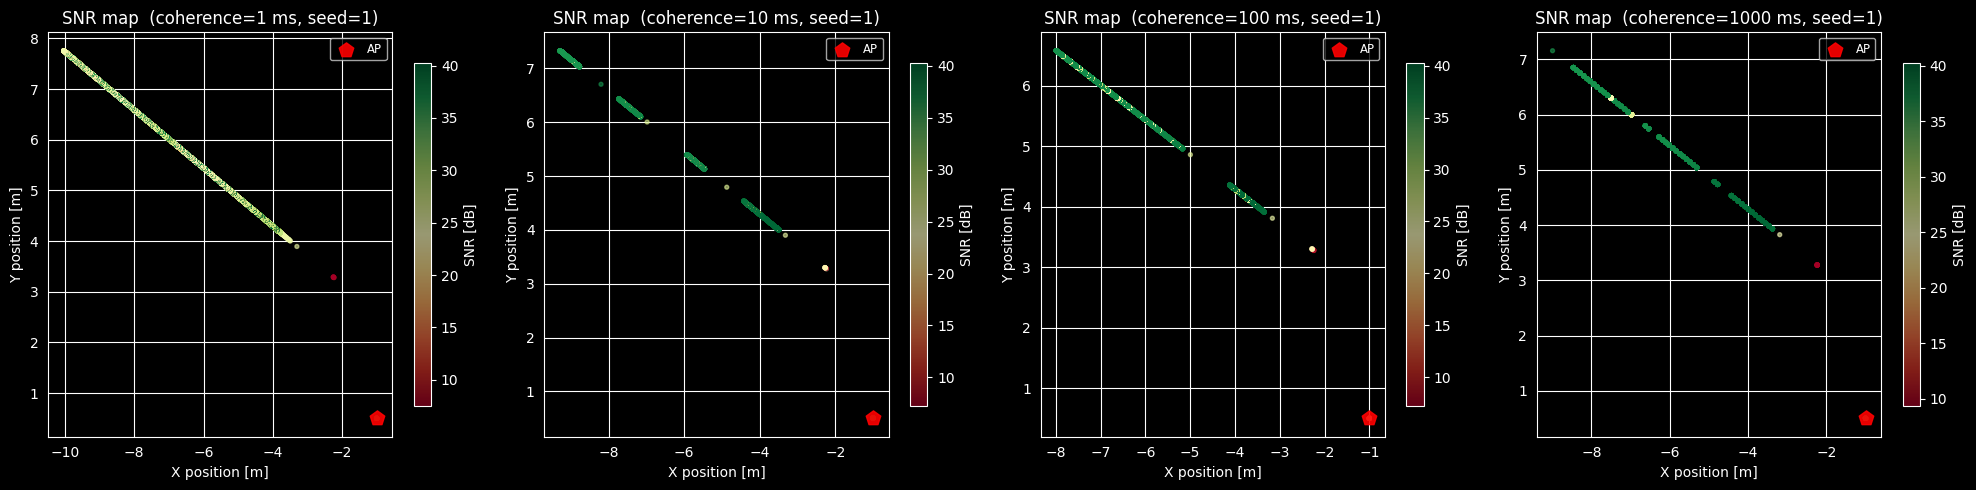

In [42]:
# ── 3. SNR heatmap on the floor-plan (seed=1 per coherence time) ─────────
# Colour = SNR value; AP shown as a red pentagon (same style as plot3d_mobile_csi.py).
ncols = len(coherence_times)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5), squeeze=False)
axes = axes[0]

for idx, tc in enumerate(coherence_times):
    ax = axes[idx]
    df = load_csv(snr_file(tc, 1))

    if df is not None and not df.empty:
        sc = ax.scatter(df['pos_x'], df['pos_y'],
                        c=df['SNR_dB'], cmap='RdYlGn',
                        s=8, alpha=0.6)
        plt.colorbar(sc, ax=ax, label='SNR [dB]', shrink=0.85)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', color='red')

    # AP marker — red pentagon, same convention as plot3d_mobile_csi.py
    ax.scatter(AP_X, AP_Y, marker='p', s=120, c='r', alpha=0.9,
               zorder=6, label='AP')
    ax.set_xlabel('X position [m]')
    ax.set_ylabel('Y position [m]')
    ax.set_title(f'SNR map  (coherence={tc} ms, seed=1)')
    ax.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.savefig('snr_spatial.png', dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


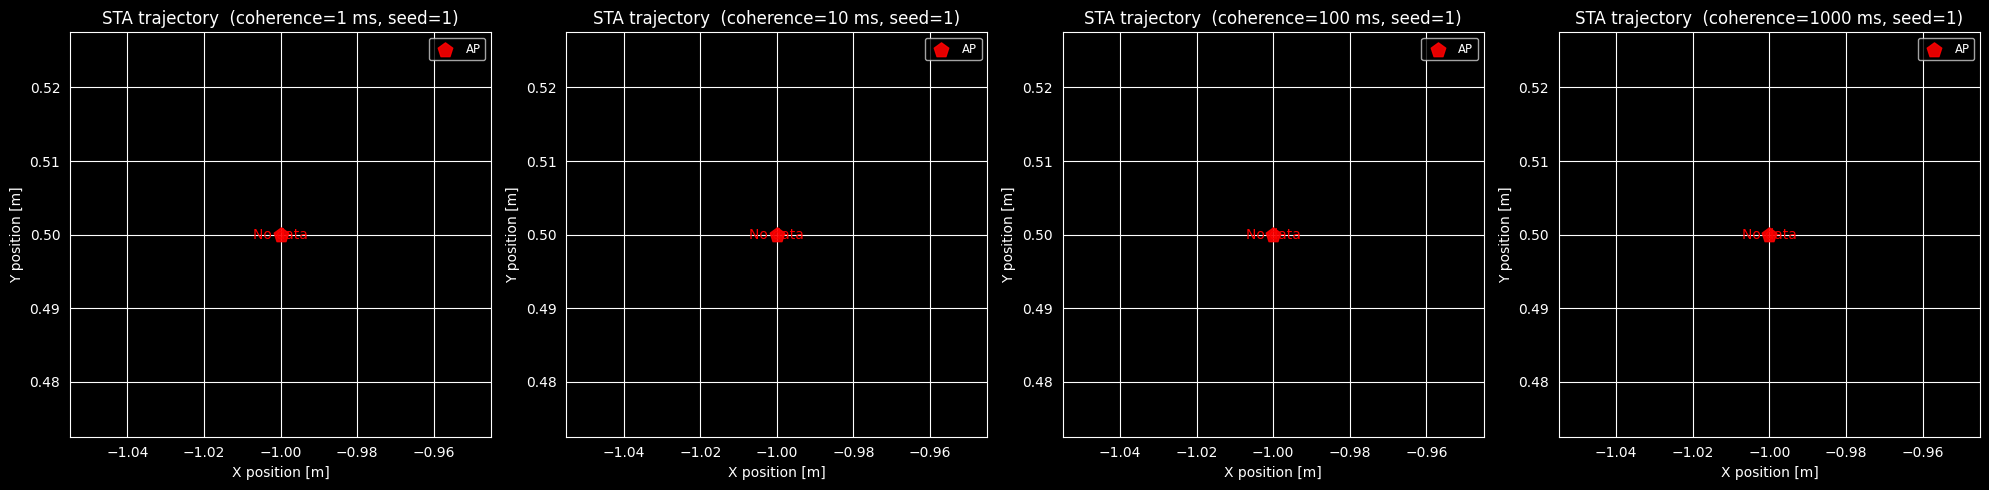

In [32]:
# ── 1. STA trajectory per coherence time (seed=1) ────────────────────────
# Colour-encodes simulation time; AP shown as a red pentagon.
ncols = len(coherence_times)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5), squeeze=False)
axes = axes[0]

for idx, tc in enumerate(coherence_times):
    ax = axes[idx]
    df = load_csv(pos_file(tc, 1))

    if df is not None and not df.empty:
        for sta_id, grp in df.groupby('STA_NodeId'):
            grp = grp.sort_values('Time_s')
            sc  = ax.scatter(grp['pos_x'], grp['pos_y'],
                             c=grp['Time_s'], cmap='plasma',
                             s=8, alpha=0.7)
            # mark the start of the walk with a triangle
            ax.scatter(grp['pos_x'].iloc[0], grp['pos_y'].iloc[0],
                       marker='^', s=80, c='lime', zorder=5, label='Start')
        plt.colorbar(sc, ax=ax, label='Time [s]', shrink=0.85)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', color='red')

    ax.scatter(AP_X, AP_Y, marker='p', s=120, c='r', alpha=0.9,
               zorder=6, label='AP')
    ax.set_xlabel('X position [m]')
    ax.set_ylabel('Y position [m]')
    ax.set_title(f'STA trajectory  (coherence={tc} ms, seed=1)')
    ax.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.savefig('positions_trajectory.png', dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


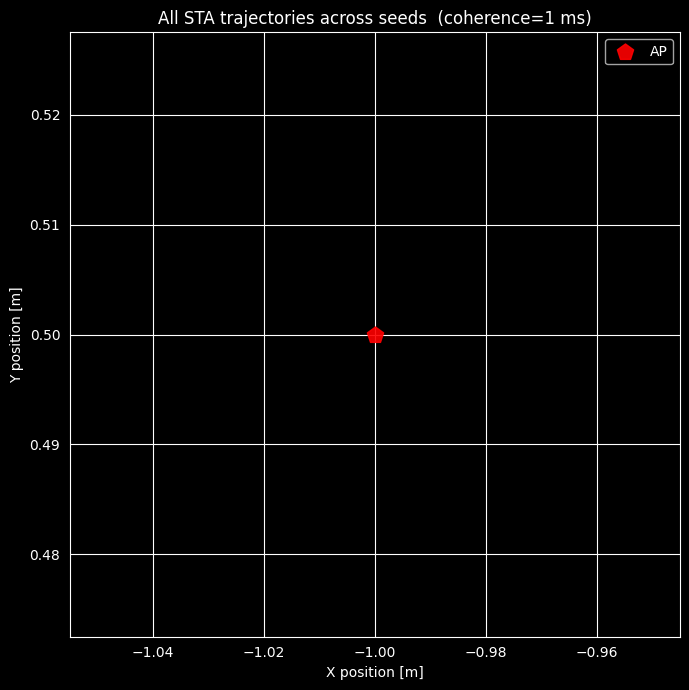

In [33]:
# ── 2. All seeds overlaid for one coherence time ─────────────────────────
# Good for checking how much trajectory variability exists across seeds.
tc_detail = coherence_times[0]
fig, ax   = plt.subplots(figsize=(7, 7))

for seed in range(1, num_seeds + 1):
    df = load_csv(pos_file(tc_detail, seed))
    if df is None or df.empty:
        continue
    for _, grp in df.groupby('STA_NodeId'):
        grp = grp.sort_values('Time_s')
        ax.plot(grp['pos_x'], grp['pos_y'], alpha=0.35, linewidth=0.9)

ax.scatter(AP_X, AP_Y, marker='p', s=150, c='r', alpha=0.9,
           zorder=6, label='AP')
ax.set_xlabel('X position [m]')
ax.set_ylabel('Y position [m]')
ax.set_title(f'All STA trajectories across seeds  (coherence={tc_detail} ms)')
ax.legend()
plt.tight_layout()
plt.savefig(f'positions_all_seeds_tc{tc_detail}.png',
            dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


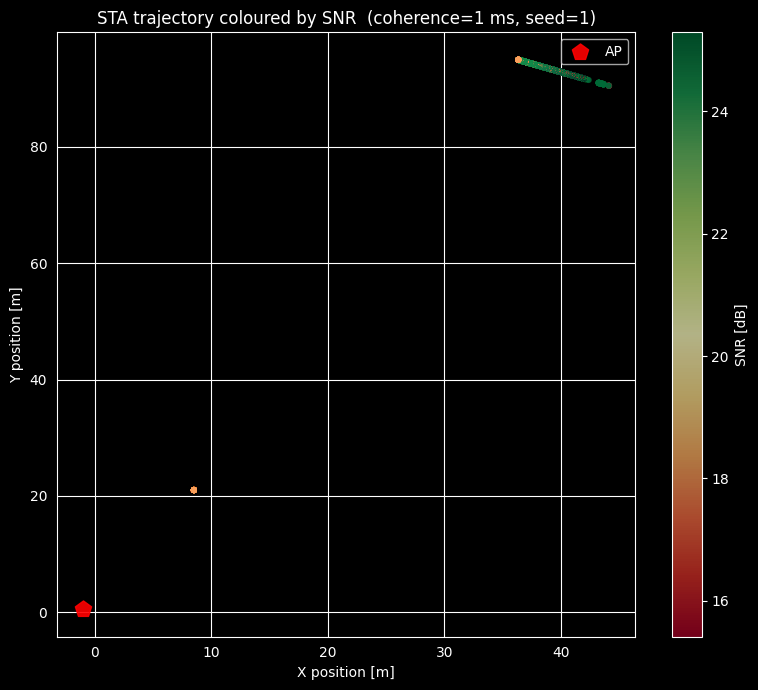

In [34]:
# ── 3. Trajectory coloured by SNR (combined snr + position data) ─────────
# Uses the SNR CSV which already contains position columns.
# This is the spatial view from plot3d_mobile_csi.py but with SNR as colour.
tc_ex = coherence_times[0]
df    = load_csv(snr_file(tc_ex, 1))   # SNR CSV already has pos_x / pos_y

fig, ax = plt.subplots(figsize=(8, 7))

if df is not None and not df.empty:
    sc = ax.scatter(df['pos_x'], df['pos_y'],
                    c=df['SNR_dB'], cmap='RdYlGn',
                    s=12, alpha=0.7)
    plt.colorbar(sc, ax=ax, label='SNR [dB]')
else:
    ax.text(0.5, 0.5, f'File not found:\n{snr_file(tc_ex, 1)}',
            transform=ax.transAxes, ha='center', va='center', color='red')

ax.scatter(AP_X, AP_Y, marker='p', s=150, c='r', alpha=0.9,
           zorder=6, label='AP')
ax.set_xlabel('X position [m]')
ax.set_ylabel('Y position [m]')
ax.set_title(f'STA trajectory coloured by SNR  (coherence={tc_ex} ms, seed=1)')
ax.legend()
plt.tight_layout()
plt.savefig(f'snr_trajectory_tc{tc_ex}.png',
            dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()
